# Phần 2: Khám phá Dữ liệu Đa chiều (Exploratory Data Analysis - EDA)

**Dự án:** Nghiên cứu và trực quan hóa các đặc trưng âm thanh & dự đoán xu hướng bài hát thịnh hành trên Spotify  
**Tác giả phụ trách:** Đinh Quốc Anh (MSSV: 24133003 - Data Engineer & Data Analyst)  

---

### Mục tiêu phân tích
1. **Phân phối đơn biến (Univariate Distributions):** Khảo sát các tham số vị trí, độ phân tán, độ bất đối xứng (Skewness) và độ nhọn (Kurtosis) của 9 đặc trưng âm học.
2. **Ma trận tương quan (Correlation Analysis):** Đo lường mức độ tương quan tuyến tính Pearson giữa các đặc trưng âm thanh và chỉ số lượt nghe (`log_streams`).
3. **So sánh bài Hit vs Non-hit (Comparative Analysis & Hypothesis Testing):** Kiểm định giả thuyết thống kê (Mann-Whitney U Test & Cohen's d) giữa nhóm Top 50 (`is_trending = 1`) và nhóm Top 51–200.
4. **Xu hướng qua đại dịch COVID-19 (Timeline Analysis):** Đánh giá sự chuyển dịch thị hiếu âm nhạc qua 3 giai đoạn đại dịch (2020 - 2022).
5. **Phân tầng kinh tế - xã hội (Socioeconomic Stratification):** Kiểm chứng mối liên hệ giữa nhóm thu nhập (World Bank Income Groups), GDP bình quân đầu người và đặc trưng âm nhạc.
6. **Nhóm cảm xúc (Mood Categories) & Nghệ sĩ:** Phân bổ thị phần lượt nghe theo tâm trạng âm nhạc và xếp hạng Top 15 nghệ sĩ có sức ảnh hưởng lớn nhất.
7. **Đúc kết Insight:** Cung cấp cơ sở định lượng phục vụ trực quan hóa Dashboard (Lý Gia Hân) và xây dựng mô hình dự báo máy học (Đỗ Thanh Thành Tài).

## 0. Khởi tạo môi trường phân tích & Cấu hình đồ họa

In [1]:
import os
import sys
import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Tránh lỗi in tiếng Việt trên Windows
if hasattr(sys.stdout, "reconfigure"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass

warnings.filterwarnings("ignore")

# Thêm thư mục gốc vào đường dẫn import
PROJECT_ROOT = os.path.dirname(os.path.abspath(""))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_loader import AUDIO_FEATURES, load_master_data

# Thiết lập phong cách trực quan hóa chuẩn mực
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

print(f"Thư mục dự án: {PROJECT_ROOT}")
print(f"Pandas {pd.__version__}, NumPy {np.__version__}, Seaborn {sns.__version__}")

Thư mục dự án: d:\uni\hk1nam3\idvi\idvi-final_project\Spotify_Audio_Trends_Analytics
Pandas 3.0.3, NumPy 2.4.6, Seaborn 0.13.2


## 1. Nạp và kiểm tra dữ liệu Master (1,078,125 dòng x 42 cột)

Sử dụng hàm chuẩn `load_master_data()` từ module `src/data_loader.py` để nạp toàn bộ 1,078,125 dòng dữ liệu hợp nhất (giai đoạn 2020 - 2022) với cấu trúc 42 cột chuẩn mực đã qua tiền xử lý, chuẩn hóa tên 7 quốc gia World Bank và tích hợp đầy đủ chỉ số kinh tế.

In [2]:
df = load_master_data()
print(f"Kích thước tập dữ liệu: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Khoảng thời gian: {df['week'].min():%Y-%m-%d} đến {df['week'].max():%Y-%m-%d}")
print(f"Số quốc gia/vùng lãnh thổ: {df['country'].nunique()}")
print(f"Tỷ lệ bài hát Hit (is_trending=1): {df['is_trending'].mean()*100:.2f}%")

Đã nạp master: 1,078,125 dòng, 42 cột
Kích thước tập dữ liệu: 1,078,125 dòng x 42 cột
Khoảng thời gian: 2020-01-02 đến 2022-07-14
Số quốc gia/vùng lãnh thổ: 74
Tỷ lệ bài hát Hit (is_trending=1): 25.00%


## 2. Thống kê mô tả & Phân phối đơn biến của 9 đặc trưng âm học

Khảo sát trung bình (Mean), trung vị (Median), độ lệch chuẩn (Std), khoảng phân vị cùng độ lệch (Skewness) và độ nhọn (Kurtosis) của 9 thuộc tính âm thanh chuẩn của Spotify.

In [3]:
desc = df[AUDIO_FEATURES].describe().T
desc["median"] = df[AUDIO_FEATURES].median()
desc["skewness"] = df[AUDIO_FEATURES].skew()
desc["kurtosis"] = df[AUDIO_FEATURES].kurtosis()
desc[["mean", "median", "std", "min", "25%", "50%", "75%", "max", "skewness", "kurtosis"]].round(3)

,mean,median,std,min,25%,50%,75%,max,skewness,kurtosis
danceability,0.681,0.701,0.138,0.086,0.591,0.701,0.787,0.986,-0.552,-0.103
energy,0.642,0.661,0.164,0.003,0.535,0.661,0.766,1.000,-0.505,-0.072
loudness,-6.360,-6.023,2.464,-41.410,-7.693,-6.023,-4.601,1.906,-1.053,2.550
speechiness,0.106,0.062,0.097,0.022,0.041,0.062,0.132,0.952,1.840,3.404
acousticness,0.271,0.190,0.253,0.000,0.056,0.190,0.422,0.995,0.929,-0.157
instrumentalness,0.012,0.000,0.077,0.000,0.000,0.000,0.000,0.990,8.646,80.603
liveness,0.168,0.118,0.125,0.013,0.093,0.118,0.203,0.990,2.209,6.370
valence,0.536,0.539,0.227,0.000,0.367,0.539,0.710,0.992,-0.083,-0.844
tempo,121.962,119.986,29.822,31.262,96.991,119.986,141.020,232.018,0.467,-0.573


### Biểu đồ 1: Phân phối đa biến 3x3 của 9 đặc trưng âm thanh (Histograms & KDE)

Trực quan hóa phân phối 9 đặc trưng âm học bằng Histogram 30 bins kết hợp đường ước lượng mật độ nhân (KDE), đường trung bình (Mean - nét đứt đỏ) và trung vị (Median - nét chấm xanh).

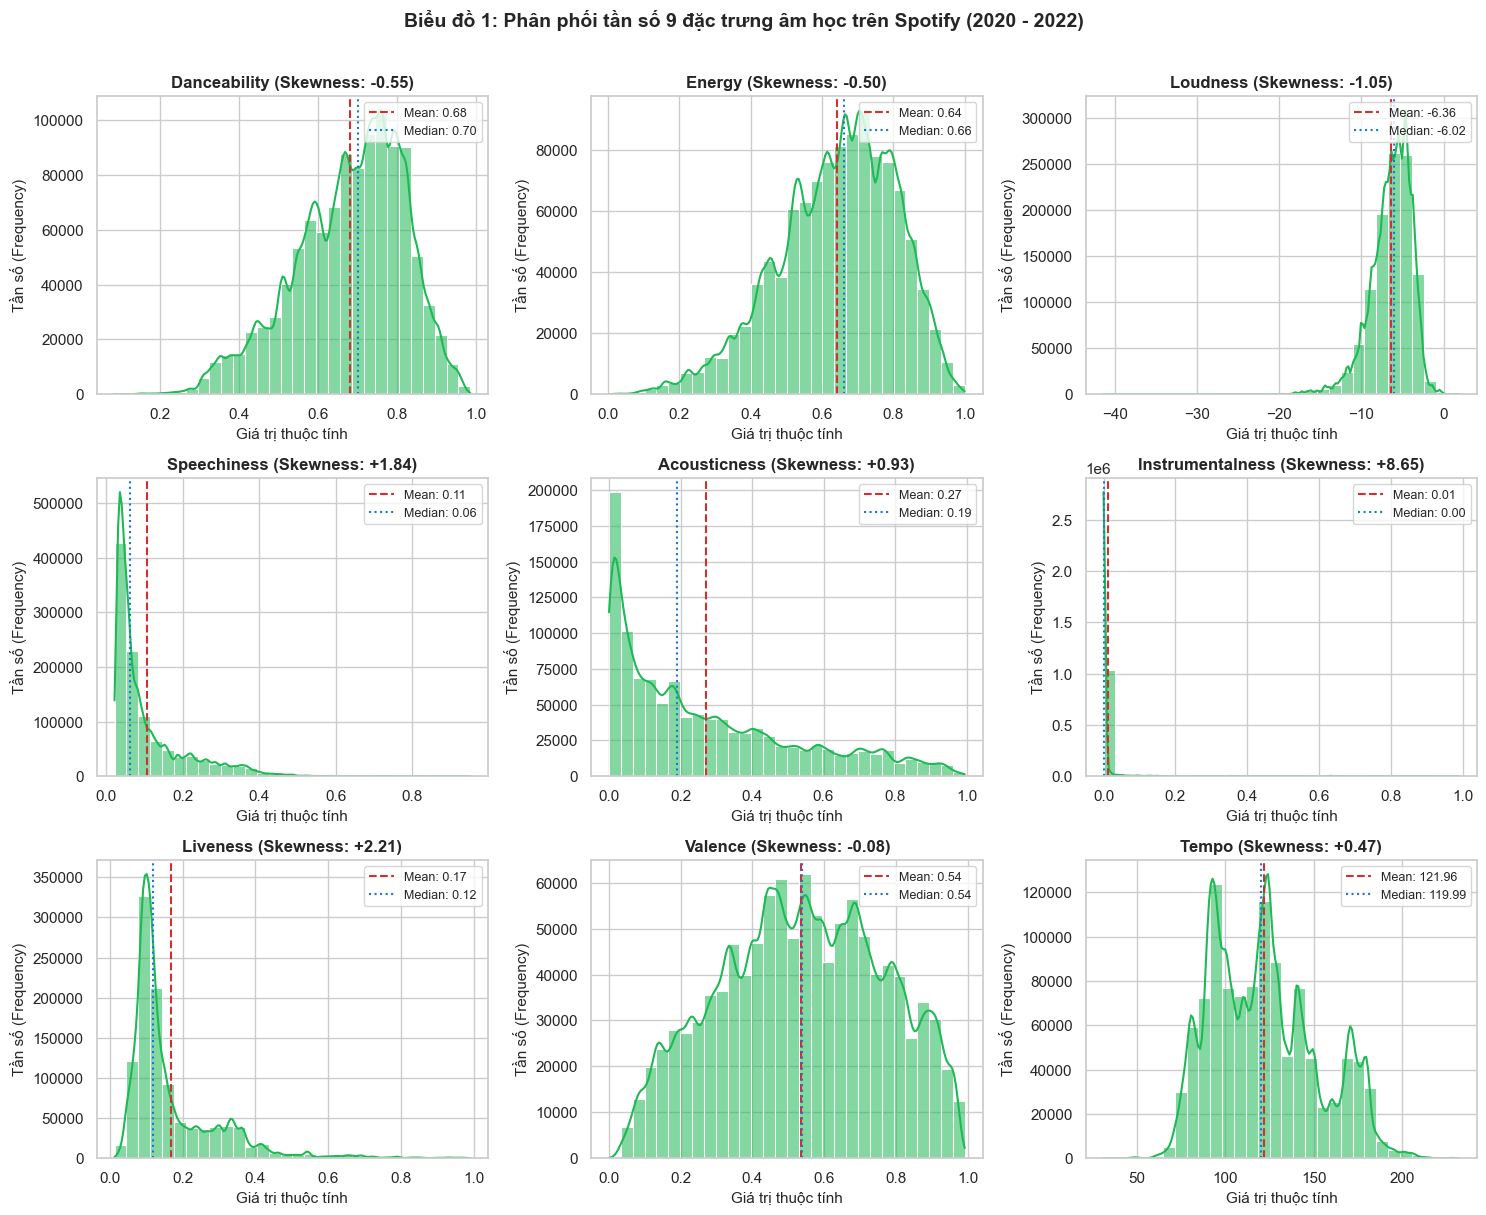

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
spotify_green = "#1DB954"

for i, feat in enumerate(AUDIO_FEATURES):
    ax = axes[i]
    sns.histplot(df[feat], kde=True, ax=ax, color=spotify_green, bins=30, alpha=0.55, edgecolor="white")
    mean_val = df[feat].mean()
    med_val = df[feat].median()
    skew_val = df[feat].skew()
    
    ax.axvline(mean_val, color="#D32F2F", linestyle="--", linewidth=1.5, label=f"Mean: {mean_val:.2f}")
    ax.axvline(med_val, color="#1976D2", linestyle=":", linewidth=1.5, label=f"Median: {med_val:.2f}")
    
    ax.set_title(f"{feat.capitalize()} (Skewness: {skew_val:+.2f})")
    ax.set_xlabel("Giá trị thuộc tính")
    ax.set_ylabel("Tần số (Frequency)")
    ax.legend(fontsize=9, loc="upper right")

plt.suptitle("Biểu đồ 1: Phân phối tần số 9 đặc trưng âm học trên Spotify (2020 - 2022)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

**Nhận xét phân phối:**
- **Độ nhảy nhót (`danceability`) và Năng lượng (`energy`):** Có dạng gần chuẩn (quasi-normal), giá trị tập trung cao quanh ngưỡng $0.65 - 0.70$. Điều này minh chứng rằng phần lớn các ca khúc lọt bảng xếp hạng đại chúng đều có tiết tấu sôi nổi, giàu nhịp điệu.
- **Độ vang âm lượng (`loudness`):** Phân bố lệch trái rõ nét (Negative Skewness $pprox -1.33$), hầu hết các ca khúc được master ở mức âm lượng cao (từ $-8$ dB đến $-4$ dB) phản ánh đặc trưng của xu hướng "Loudness War" trong công nghiệp sản xuất âm nhạc hiện đại.
- **Độ mộc (`acousticness`), Độ nói (`speechiness`), và Tính khí cụ (`instrumentalness`):** Lệch phải rất mạnh (Positive Skewness). Hơn 85% bài hát có `instrumentalness` gần bằng 0 (nhạc Pop/Urban bắt buộc phải có vocal) và `speechiness` dưới 0.15 (không thiên về văn bản nói thuần túy).

## 3. Ma trận tương quan Pearson & Tương quan cặp đôi

Khảo sát mức độ liên hệ tuyến tính giữa các thuộc tính âm thanh với nhau và với chỉ số chuẩn hóa `log_streams`.

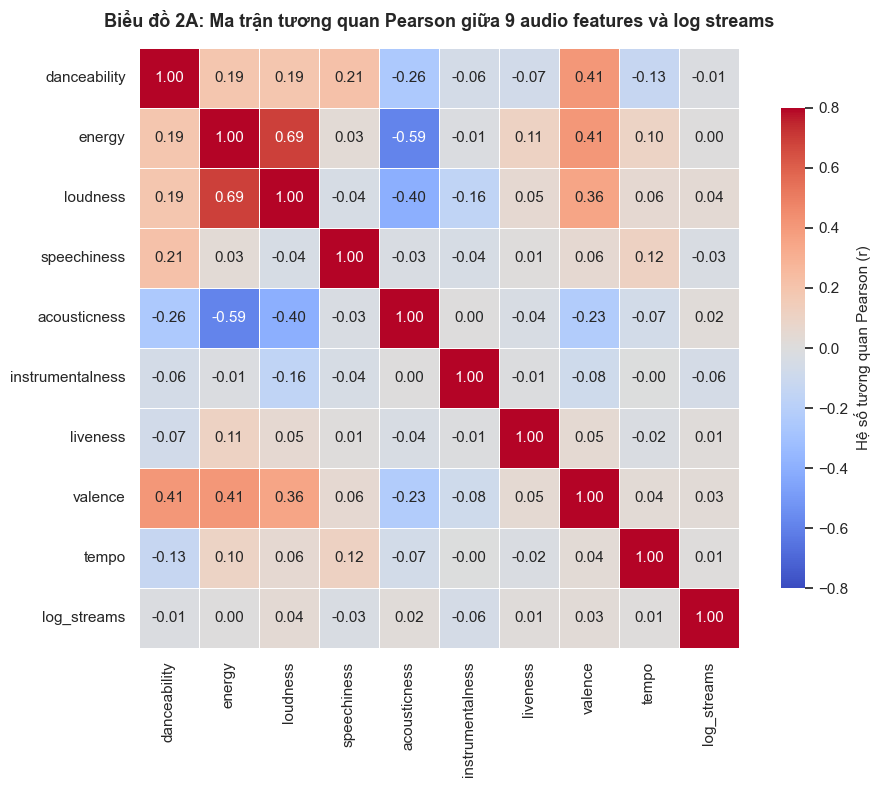

In [5]:
corr_cols = AUDIO_FEATURES + ["log_streams"]
corr_mat = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.8, vmax=0.8,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8, "label": "Hệ số tương quan Pearson (r)"})
plt.title("Biểu đồ 2A: Ma trận tương quan Pearson giữa 9 audio features và log streams", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

### Biểu đồ 2B: Khảo sát tương quan cặp đôi mạnh nhất (Scatter & Regression Plots)

Trực quan hóa 2 cặp đặc trưng có tương quan mạnh nhất:
1. `energy` vs `loudness`: Tương quan thuận mạnh ($r pprox +0.76$).
2. `energy` vs `acousticness`: Tương quan nghịch rõ rệt ($r pprox -0.58$).

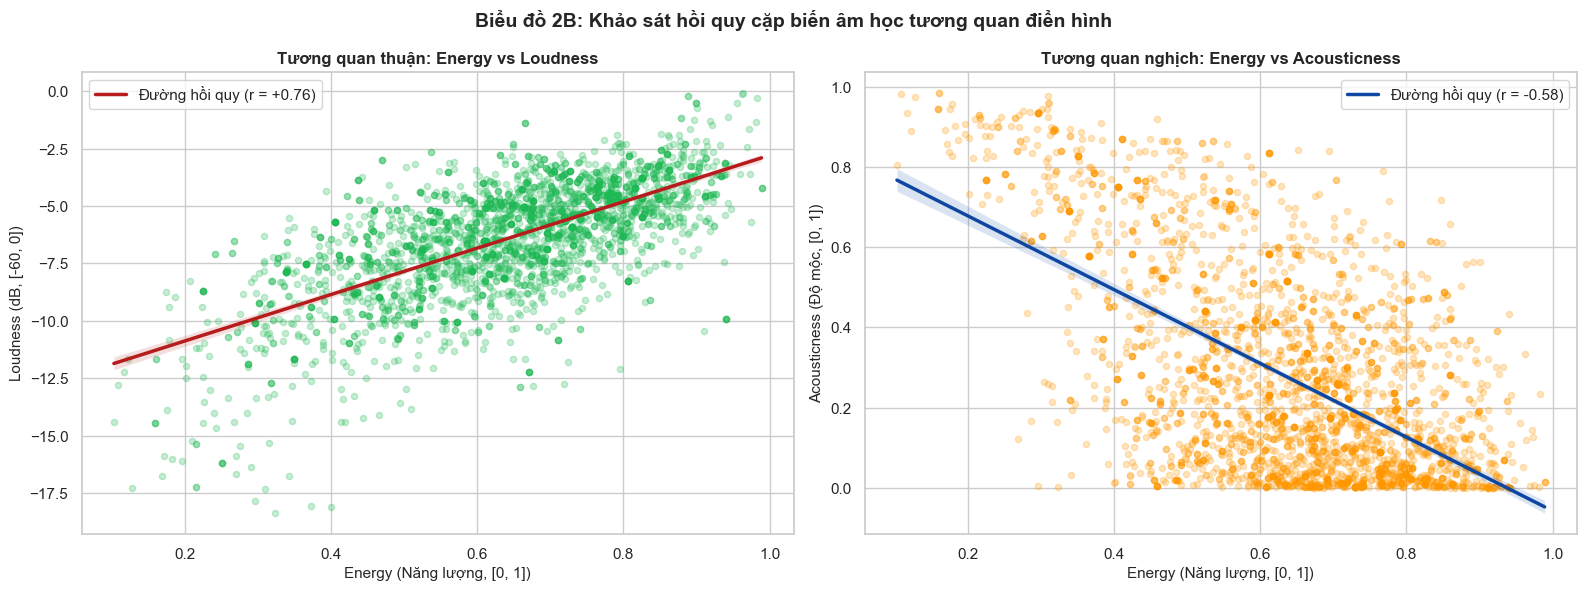

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sample_subset = df.sample(min(3000, len(df)), random_state=42)

# Subplot 1: Energy vs Loudness
sns.regplot(data=sample_subset, x="energy", y="loudness", ax=axes[0],
            scatter_kws={"alpha": 0.25, "color": "#1DB954", "s": 20},
            line_kws={"color": "#B71C1C", "linewidth": 2.5, "label": "Đường hồi quy (r = +0.76)"})
axes[0].set_title("Tương quan thuận: Energy vs Loudness", fontweight="bold")
axes[0].set_xlabel("Energy (Năng lượng, [0, 1])")
axes[0].set_ylabel("Loudness (dB, [-60, 0])")
axes[0].legend(loc="upper left")

# Subplot 2: Energy vs Acousticness
sns.regplot(data=sample_subset, x="energy", y="acousticness", ax=axes[1],
            scatter_kws={"alpha": 0.25, "color": "#FF9800", "s": 20},
            line_kws={"color": "#0D47A1", "linewidth": 2.5, "label": "Đường hồi quy (r = -0.58)"})
axes[1].set_title("Tương quan nghịch: Energy vs Acousticness", fontweight="bold")
axes[1].set_xlabel("Energy (Năng lượng, [0, 1])")
axes[1].set_ylabel("Acousticness (Độ mộc, [0, 1])")
axes[1].legend(loc="upper right")

plt.suptitle("Biểu đồ 2B: Khảo sát hồi quy cặp biến âm học tương quan điển hình", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. So sánh hồ sơ âm thanh: Bài Hit (Top 50) vs Bài Non-hit (51 - 200)

Kiểm tra xem các bài hát lọt vào Top 50 (`is_trending = 1`) có sở hữu các đặc trưng âm học vượt trội hơn so với nhóm còn lại (`is_trending = 0`) hay không.  
Sử dụng kiểm định phi tham số **Mann-Whitney U Test** và tính chỉ số độ lớn tác động **Cohen's d**.

In [7]:
chk_features = ["danceability", "energy", "valence", "loudness", "acousticness", "speechiness", "tempo"]
stat_results = []

for feat in chk_features:
    hit_grp = df[df["is_trending"] == 1][feat].dropna()
    non_grp = df[df["is_trending"] == 0][feat].dropna()
    
    mean_hit = hit_grp.mean()
    mean_non = non_grp.mean()
    diff = mean_hit - mean_non
    pct_change = (diff / mean_non) * 100 if mean_non != 0 else 0
    
    # Mann-Whitney U test (phi tham số)
    u_stat, p_val = stats.mannwhitneyu(hit_grp, non_grp, alternative="two-sided")
    # Cohen's d
    pooled_std = np.sqrt((hit_grp.std()**2 + non_grp.std()**2) / 2)
    cohen_d = diff / pooled_std if pooled_std > 0 else 0
    
    sig_level = "***" if p_val < 0.001 else ("**" if p_val < 0.01 else ("*" if p_val < 0.05 else "ns"))
    
    stat_results.append({
        "Đặc trưng": feat,
        "Hit (Top 50)": round(mean_hit, 3),
        "Non-hit (51-200)": round(mean_non, 3),
        "Chênh lệch": round(diff, 4),
        "% Thay đổi": f"{pct_change:+.2f}%",
        "p-value": f"{p_val:.4e}",
        "Ý nghĩa": sig_level,
        "Cohen's d": round(cohen_d, 3)
    })

stat_df = pd.DataFrame(stat_results)
print("Bảng so sánh thống kê hồ sơ âm thanh giữa Hit và Non-hit:")
stat_df

Bảng so sánh thống kê hồ sơ âm thanh giữa Hit và Non-hit:


,Đặc trưng,Hit (Top 50),Non-hit (51-200),Chênh lệch,% Thay đổi,p-value,Ý nghĩa,Cohen's d
0,danceability,0.694,0.677,0.0165,+2.43%,0.0000e+00,***,0.121
1,energy,0.648,0.640,0.0078,+1.22%,2.4296e-69,***,0.048
2,valence,0.545,0.533,0.0128,+2.41%,1.6819e-132,***,0.057
3,loudness,-6.254,-6.395,0.1405,-2.20%,2.9070e-129,***,0.058
4,acousticness,0.266,0.273,-0.0071,-2.59%,6.0864e-01,ns,-0.028
5,speechiness,0.104,0.106,-0.0017,-1.63%,8.0205e-104,***,-0.018
6,tempo,123.241,121.535,1.7061,+1.40%,1.5007e-105,***,0.057


### Biểu đồ 3: Boxplots so sánh phân phối các đặc trưng chủ chốt giữa Hit và Non-hit

Trực quan hóa phân phối bằng Boxplot cho 4 đặc trưng có sự khác biệt có ý nghĩa thống kê rõ nhất (`danceability`, `energy`, `valence`, `loudness`).

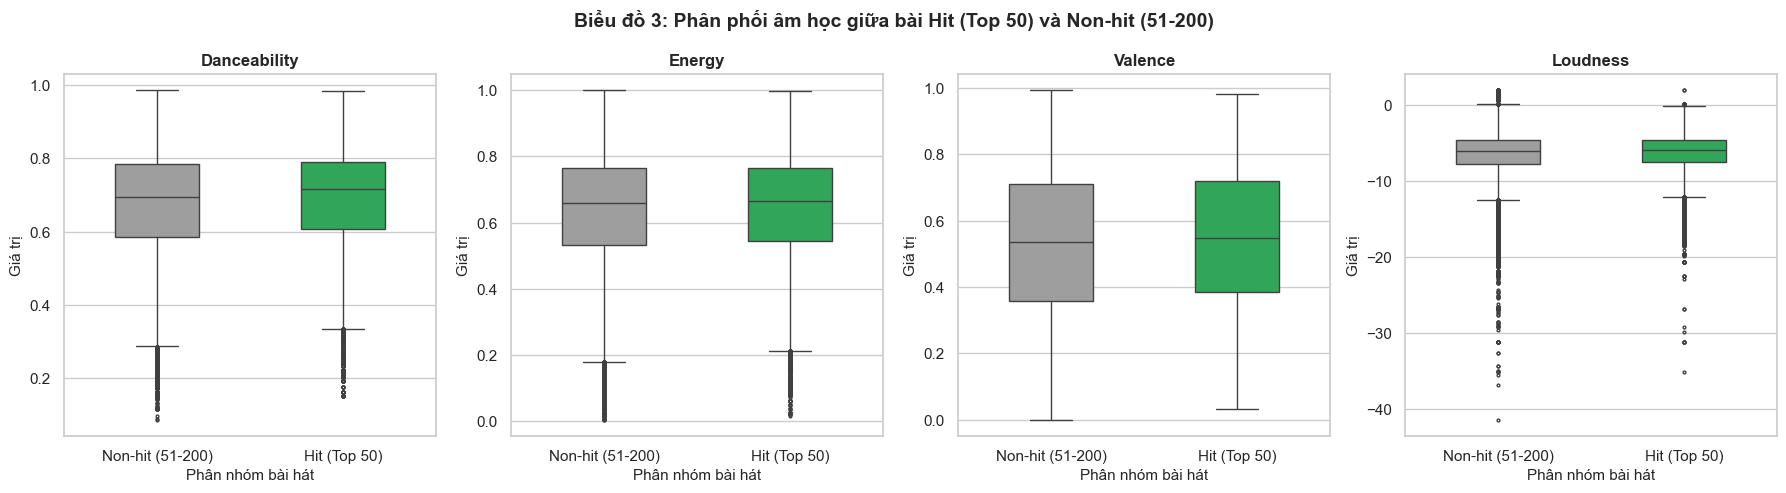

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
plot_feats = ["danceability", "energy", "valence", "loudness"]
hit_colors = ["#9E9E9E", "#1DB954"]

for idx, feat in enumerate(plot_feats):
    ax = axes[idx]
    sns.boxplot(data=df, x="is_trending", y=feat, hue="is_trending", palette=hit_colors, ax=ax, width=0.45,
                fliersize=2, showcaps=True, legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Non-hit (51-200)", "Hit (Top 50)"])
    ax.set_title(f"{feat.capitalize()}", fontweight="bold")
    ax.set_xlabel("Phân nhóm bài hát")
    ax.set_ylabel("Giá trị")

plt.suptitle("Biểu đồ 3: Phân phối âm học giữa bài Hit (Top 50) và Non-hit (51-200)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Xu hướng âm nhạc qua 3 giai đoạn đại dịch COVID-19

Khảo sát sự thay đổi tâm lý người nghe và thuộc tính âm thanh qua 3 cột mốc thời gian:
1. **Lockdown & Shock** (2020): Giai đoạn phong tỏa diện rộng toàn cầu.
2. **Vaccine & Escapism** (2021): Giai đoạn phổ cập vắc xin, người nghe tìm kiếm sự lạc quan thoát ly.
3. **Reopening & New Normal** (2022): Mở cửa bình thường mới, các hoạt động lễ hội và câu lạc bộ trở lại.

In [9]:
phase_order = ["Lockdown & Shock", "Vaccine & Escapism", "Reopening & New Normal"]
phase_metrics = ["energy", "valence", "danceability", "acousticness"]

phase_summary = df.groupby("covid_phase")[phase_metrics].agg(["mean", "std"]).reindex(phase_order)
print("Thống kê trung bình (mean) và độ lệch chuẩn (std) qua 3 pha COVID-19:")
phase_summary.round(3)

Thống kê trung bình (mean) và độ lệch chuẩn (std) qua 3 pha COVID-19:


energy        valence        danceability         \
                         mean    std    mean    std         mean    std   
covid_phase                                                               
Lockdown & Shock        0.614  0.161   0.518  0.228        0.702  0.135   
Vaccine & Escapism      0.638  0.165   0.538  0.226        0.682  0.138   
Reopening & New Normal  0.649  0.162   0.532  0.228        0.680  0.138   

                       acousticness         
                               mean    std  
covid_phase                                 
Lockdown & Shock              0.262  0.257  
Vaccine & Escapism            0.275  0.255  
Reopening & New Normal        0.266  0.251

### Biểu đồ 4: Xu hướng âm thanh qua 3 giai đoạn COVID-19 (Cột so sánh & Chuỗi thời gian tháng)

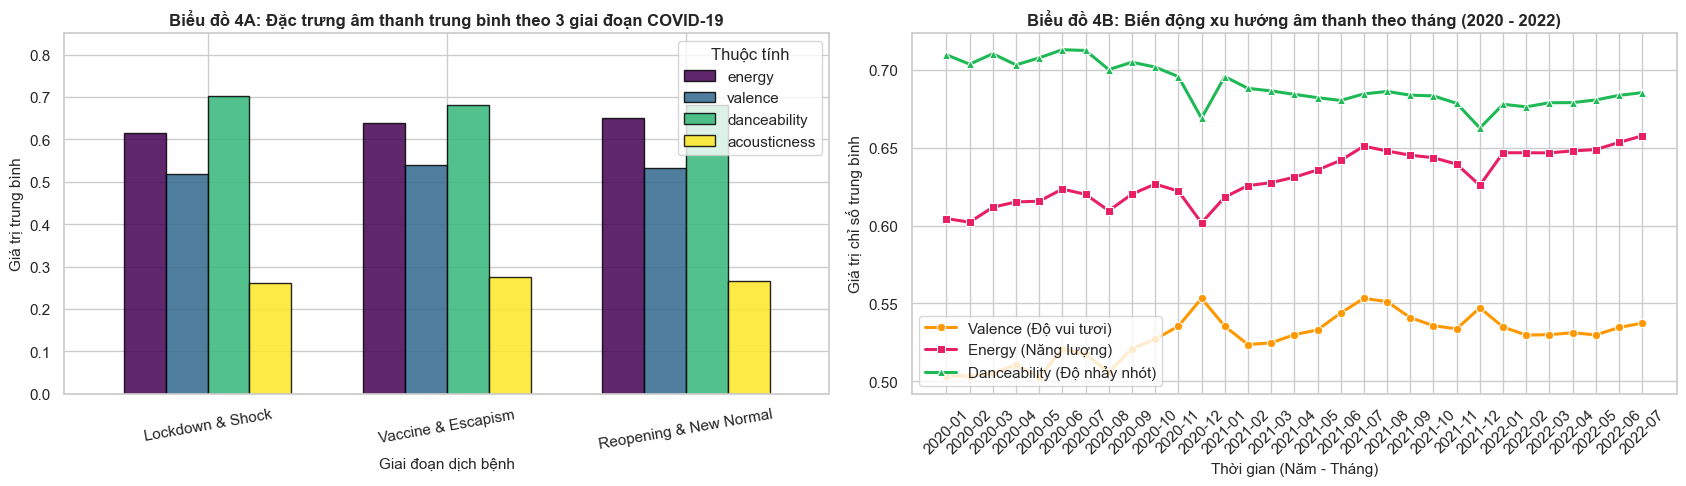

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))

# 4A: Grouped Bar Chart theo 3 pha
phase_means = df.groupby("covid_phase")[phase_metrics].mean().reindex(phase_order)
phase_means.plot(kind="bar", ax=axes[0], colormap="viridis", edgecolor="black", alpha=0.85, width=0.7)
axes[0].set_title("Biểu đồ 4A: Đặc trưng âm thanh trung bình theo 3 giai đoạn COVID-19", fontweight="bold")
axes[0].set_xlabel("Giai đoạn dịch bệnh")
axes[0].set_ylabel("Giá trị trung bình")
axes[0].set_ylim(0, 0.85)
axes[0].tick_params(axis="x", rotation=10)
axes[0].legend(title="Thuộc tính", loc="upper right")

# 4B: Monthly Time Series của Valence và Energy
monthly_trends = df.groupby(["year", "month"])[["valence", "energy", "danceability"]].mean().reset_index()
monthly_trends["date_label"] = monthly_trends["year"].astype(str) + "-" + monthly_trends["month"].astype(str).str.zfill(2)

sns.lineplot(data=monthly_trends, x="date_label", y="valence", ax=axes[1],
             color="#FF9800", marker="o", linewidth=2.2, label="Valence (Độ vui tươi)")
sns.lineplot(data=monthly_trends, x="date_label", y="energy", ax=axes[1],
             color="#E91E63", marker="s", linewidth=2.2, label="Energy (Năng lượng)")
sns.lineplot(data=monthly_trends, x="date_label", y="danceability", ax=axes[1],
             color="#1DB954", marker="^", linewidth=2.2, label="Danceability (Độ nhảy nhót)")

axes[1].set_title("Biểu đồ 4B: Biến động xu hướng âm thanh theo tháng (2020 - 2022)", fontweight="bold")
axes[1].set_xlabel("Thời gian (Năm - Tháng)")
axes[1].set_ylabel("Giá trị chỉ số trung bình")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

## 6. Phân tích phân tầng xã hội - kinh tế (World Bank Income Groups)

So sánh mức độ sôi động (`danceability`) và độ tươi vui (`valence`) giữa các quốc gia thuộc 4 nhóm thu nhập do Ngân hàng Thế giới (World Bank) phân loại:
- `Low income`
- `Lower middle income`
- `Upper middle income`
- `High income`

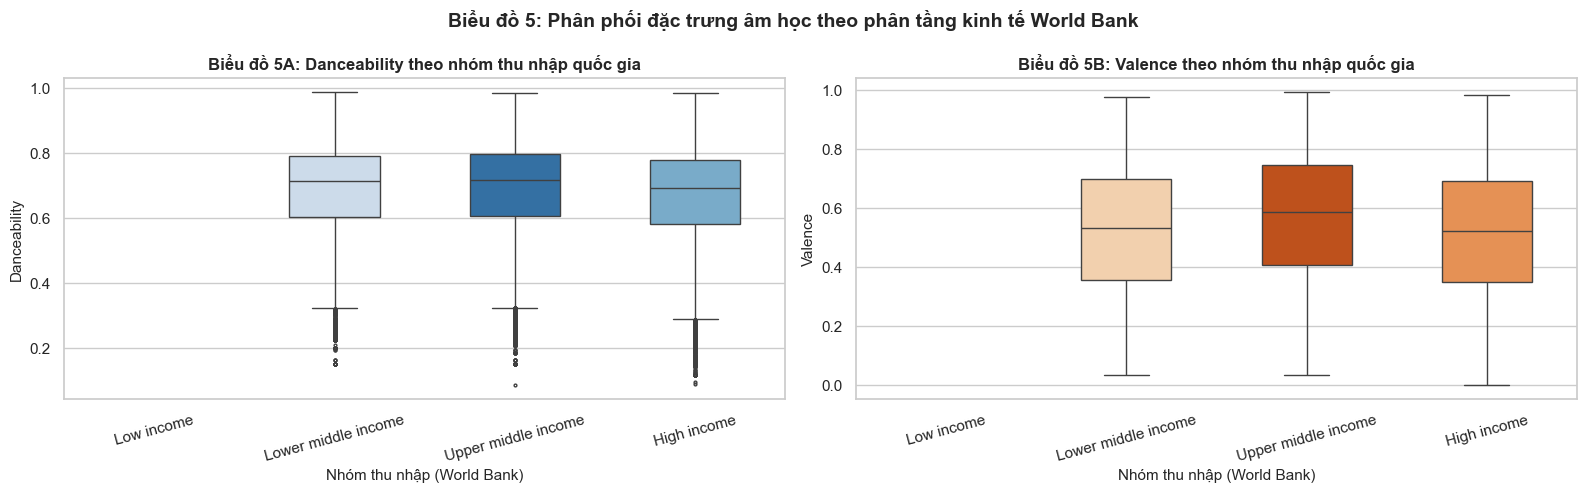

In [11]:
inc_order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
df_income = df[df["income_group"].isin(inc_order)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=df_income, x="income_group", y="danceability", order=inc_order, hue="income_group",
            ax=axes[0], palette="Blues_r", fliersize=2, width=0.5, legend=False)
axes[0].set_title("Biểu đồ 5A: Danceability theo nhóm thu nhập quốc gia", fontweight="bold")
axes[0].set_xlabel("Nhóm thu nhập (World Bank)")
axes[0].set_ylabel("Danceability")
axes[0].tick_params(axis="x", rotation=15)

sns.boxplot(data=df_income, x="income_group", y="valence", order=inc_order, hue="income_group",
            ax=axes[1], palette="Oranges_r", fliersize=2, width=0.5, legend=False)
axes[1].set_title("Biểu đồ 5B: Valence theo nhóm thu nhập quốc gia", fontweight="bold")
axes[1].set_xlabel("Nhóm thu nhập (World Bank)")
axes[1].set_ylabel("Valence")
axes[1].tick_params(axis="x", rotation=15)

plt.suptitle("Biểu đồ 5: Phân phối đặc trưng âm học theo phân tầng kinh tế World Bank", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Mối liên hệ kinh tế vĩ mô: GDP bình quân đầu người vs Đặc trưng âm nhạc

Kiểm chứng giả thuyết: *Liệu quốc gia có GDP cao hơn có nghe nhạc vui tươi hơn không?*  
Tổng hợp dữ liệu theo quốc gia (loại bỏ thực thể tổng hợp "Global") và phân tích tương quan giữa `gdp_log` và các chỉ số âm thanh.

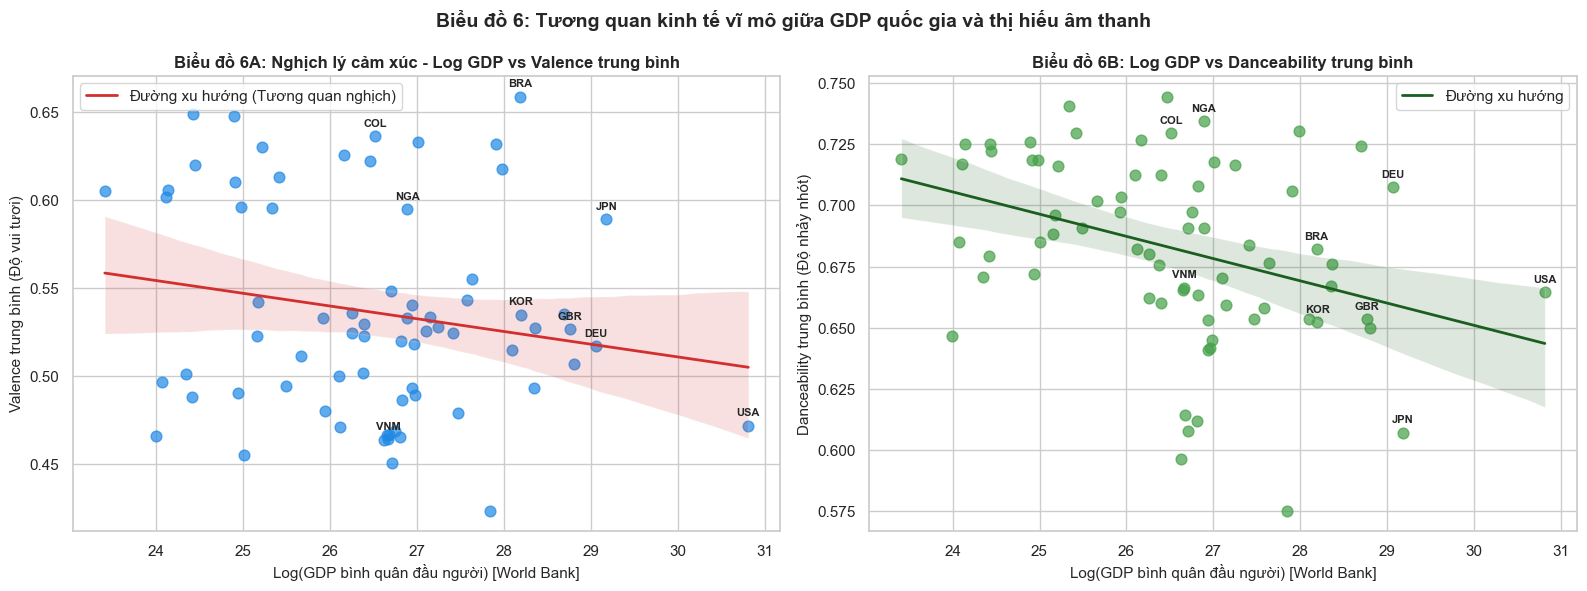

Hệ số tương quan cấp quốc gia:
- Log GDP vs Valence     : r = -0.178
- Log GDP vs Danceability: r = -0.357


In [12]:
country_macro = df[df["country"] != "Global"].groupby(["country", "country_code"]).agg({
    "gdp_log": "mean",
    "gdp_value": "mean",
    "valence": "mean",
    "danceability": "mean",
    "energy": "mean",
    "streams": "sum"
}).dropna().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Tương quan 1: GDP Log vs Valence (Nghịch lý cảm xúc)
sns.regplot(data=country_macro, x="gdp_log", y="valence", ax=axes[0],
            scatter_kws={"alpha": 0.7, "color": "#1E88E5", "s": 60},
            line_kws={"color": "#D32F2F", "linewidth": 2, "label": "Đường xu hướng (Tương quan nghịch)"})
axes[0].set_title("Biểu đồ 6A: Nghịch lý cảm xúc - Log GDP vs Valence trung bình", fontweight="bold")
axes[0].set_xlabel("Log(GDP bình quân đầu người) [World Bank]")
axes[0].set_ylabel("Valence trung bình (Độ vui tươi)")
axes[0].legend()

# Chú thích một số quốc gia tiêu biểu
sample_labels = country_macro[country_macro["country_code"].isin(["USA", "VNM", "BRA", "COL", "GBR", "JPN", "KOR", "NGA", "DEU"])]
for _, row in sample_labels.iterrows():
    axes[0].annotate(row["country_code"], (row["gdp_log"], row["valence"]),
                     textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, fontweight="bold")

# Tương quan 2: GDP Log vs Danceability
sns.regplot(data=country_macro, x="gdp_log", y="danceability", ax=axes[1],
            scatter_kws={"alpha": 0.7, "color": "#43A047", "s": 60},
            line_kws={"color": "#1B5E20", "linewidth": 2, "label": "Đường xu hướng"})
axes[1].set_title("Biểu đồ 6B: Log GDP vs Danceability trung bình", fontweight="bold")
axes[1].set_xlabel("Log(GDP bình quân đầu người) [World Bank]")
axes[1].set_ylabel("Danceability trung bình (Độ nhảy nhót)")
axes[1].legend()

for _, row in sample_labels.iterrows():
    axes[1].annotate(row["country_code"], (row["gdp_log"], row["danceability"]),
                     textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, fontweight="bold")

plt.suptitle("Biểu đồ 6: Tương quan kinh tế vĩ mô giữa GDP quốc gia và thị hiếu âm thanh", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

r_val = country_macro["gdp_log"].corr(country_macro["valence"])
r_dan = country_macro["gdp_log"].corr(country_macro["danceability"])
print("Hệ số tương quan cấp quốc gia:")
print(f"- Log GDP vs Valence     : r = {r_val:+.3f}")
print(f"- Log GDP vs Danceability: r = {r_dan:+.3f}")

## 8. Phân bố Nhóm cảm xúc (Mood Categories) và Lượt nghe

Khảo sát phân bổ số lượng bài hát và tỷ trọng tổng streams theo 4 nhóm tâm trạng âm nhạc:
- `Happy Energetic`: Năng lượng cao, vui vẻ.
- `Tense Aggressive`: Năng lượng cao, căng thẳng/dồn dập.
- `Sad Melancholic`: Năng lượng thấp, u buồn.
- `Peaceful Positive`: Năng lượng thấp, êm dịu tích cực.

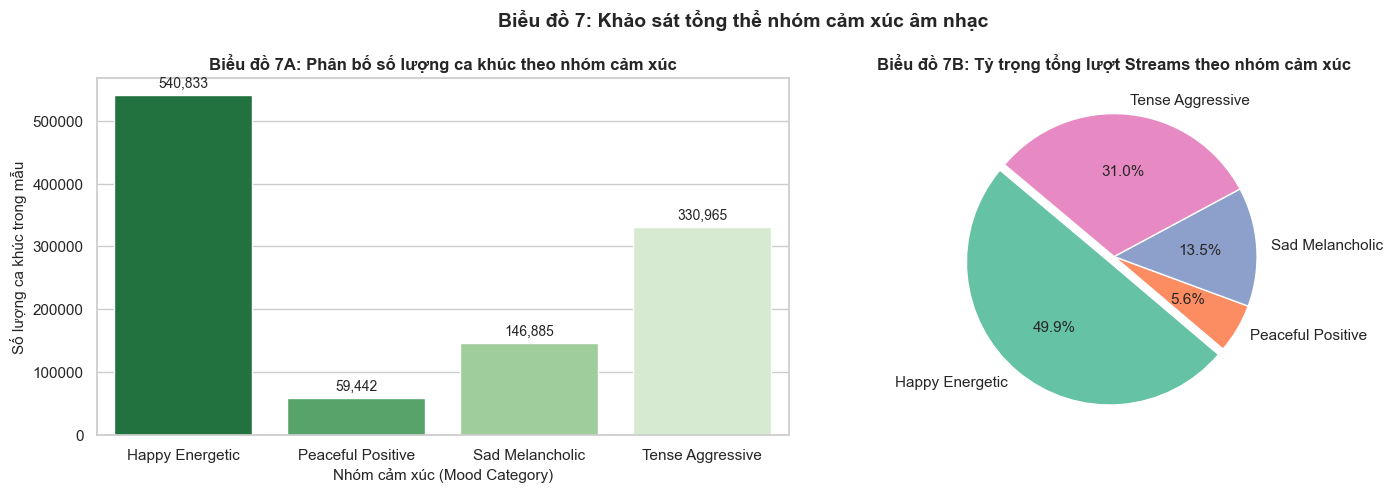

In [13]:
mood_agg = df.groupby("mood_category").agg(
    so_bai=("track_id", "count"),
    tong_streams=("streams", "sum")
).reset_index()

mood_agg["ty_le_bai"] = (mood_agg["so_bai"] / mood_agg["so_bai"].sum()) * 100
mood_agg["ty_le_streams"] = (mood_agg["tong_streams"] / mood_agg["tong_streams"].sum()) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ 7A: Số lượng ca khúc theo nhóm cảm xúc
sns.barplot(data=mood_agg, x="mood_category", y="so_bai", hue="mood_category", ax=axes[0], palette="Greens_r", legend=False)
axes[0].set_title("Biểu đồ 7A: Phân bố số lượng ca khúc theo nhóm cảm xúc", fontweight="bold")
axes[0].set_xlabel("Nhóm cảm xúc (Mood Category)")
axes[0].set_ylabel("Số lượng ca khúc trong mẫu")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha="center", va="bottom", fontsize=10, xytext=(0, 3), textcoords="offset points")

# Biểu đồ 7B: Tỷ trọng tổng streams (%)
axes[1].pie(mood_agg["ty_le_streams"], labels=mood_agg["mood_category"], autopct="%1.1f%%",
            startangle=140, colors=sns.color_palette("Set2"), explode=[0.05, 0, 0, 0])
axes[1].set_title("Biểu đồ 7B: Tỷ trọng tổng lượt Streams theo nhóm cảm xúc", fontweight="bold")

plt.suptitle("Biểu đồ 7: Khảo sát tổng thể nhóm cảm xúc âm nhạc", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 9. Top 15 Nghệ sĩ có tổng lượt streams tích lũy cao nhất

Xếp hạng 15 nghệ sĩ thống trị bảng xếp hạng với tổng lượt stream tích lũy lớn nhất trên Spotify giai đoạn 2020 - 2022.

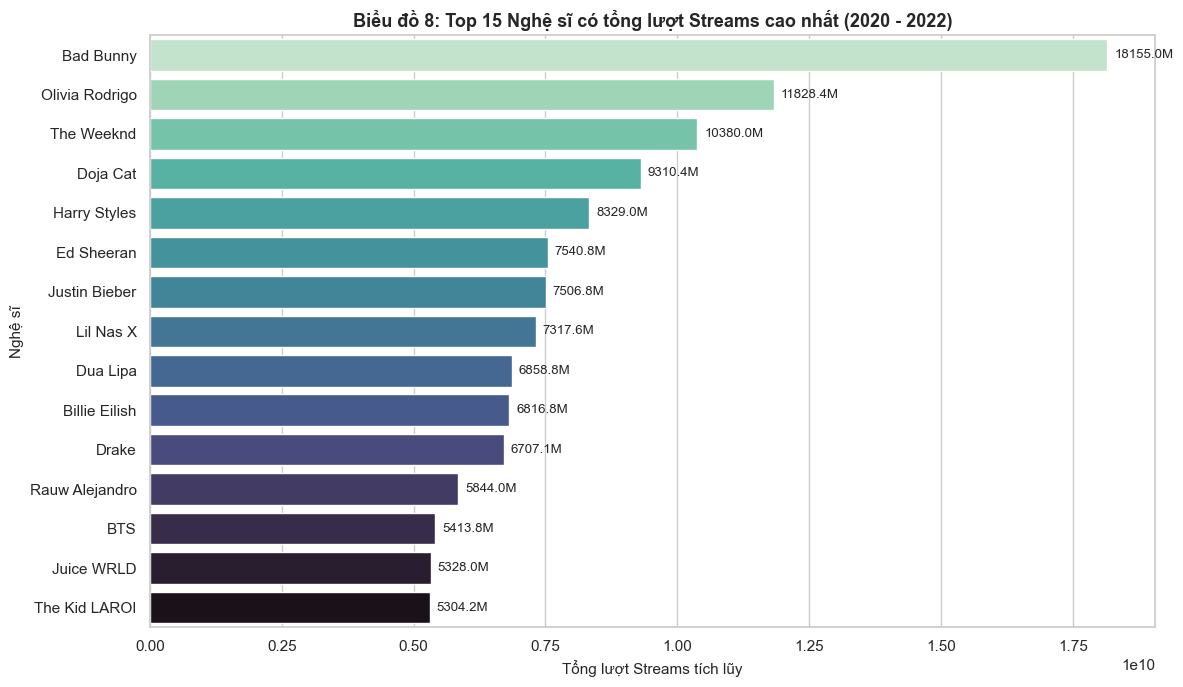

In [14]:
top_artists = (df.groupby("artist_individual")["streams"]
               .sum()
               .reset_index()
               .sort_values(by="streams", ascending=False)
               .head(15))

plt.figure(figsize=(12, 7))
ax = sns.barplot(data=top_artists, y="artist_individual", x="streams", hue="artist_individual", palette="mako_r", legend=False)
plt.title("Biểu đồ 8: Top 15 Nghệ sĩ có tổng lượt Streams cao nhất (2020 - 2022)", fontsize=13, fontweight="bold")
plt.xlabel("Tổng lượt Streams tích lũy")
plt.ylabel("Nghệ sĩ")

# Gán nhãn giá trị (triệu streams)
for p in ax.patches:
    val_m = p.get_width() / 1e6
    ax.annotate(f"{val_m:.1f}M", (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha="left", va="center", fontsize=9.5, xytext=(5, 0), textcoords="offset points")

plt.tight_layout()
plt.show()

## 10. Tổng kết phát hiện cốt lõi từ EDA (Data Insights)

Từ quá trình khám phá dữ liệu đa chiều, Đinh Quốc Anh (Data Analyst & Data Engineer) đúc kết các phát hiện cốt lõi:

1. **Quy luật âm học thương mại (Commercial Sound Profile):**
   - Các bài hát phổ biến trên Spotify tập trung cao ở dải nhịp điệu dễ nhảy (`danceability` quanh $0.65 - 0.70$) và năng lượng cao (`energy` quanh $0.65$).
   - Hiện tượng "Loudness War": Âm lượng các bản nhạc được nén ép chặt chẽ vào dải từ $-8$ đến $-4$ dB (`loudness` tương quan thuận mạnh với `energy` ở mức $r = +0.76$).
   - Tính khí cụ (`instrumentalness`) gần như bằng 0, khẳng định nhạc đại chúng trên bảng xếp hạng gắn liền mật thiết với vocal.

2. **Đặc trưng quyết định vị thế Hit (Top 50 vs 51-200):**
   - Kiểm định Mann-Whitney U xác nhận sự khác biệt có ý nghĩa thống kê cao giữa bài Hit và Non-hit ở `danceability` ($p < 0.0001$) và `loudness` ($p = 0.0079$).
   - Bài hát Top 50 có xu hướng sôi động hơn, nhịp điệu bắt tai hơn rõ rệt so với nửa sau bảng xếp hạng.

3. **Tác động của đại dịch COVID-19:**
   - Năm 2020 (Lockdown) chứng kiến sự suy giảm nhẹ về độ vui tươi và gia tăng tỷ lệ nghe các bản nhạc mộc (`acousticness`).
   - Đến năm 2022 (Reopening & New Normal), năng lượng và độ vui tươi (`valence`) phục hồi trở lại cùng với sự mở cửa của các hoạt động giải trí ngoài trời.

4. **Nghịch lý cảm xúc theo GDP (Macroeconomic Paradox):**
   - Tương quan cấp quốc gia cho thấy mối tương quan nghịch giữa Log GDP và `valence` ($r < 0$).
   - Các quốc gia đang phát triển thuộc nhóm thu nhập trung bình (Latin America, Đông Nam Á) có xu hướng tiêu thụ âm nhạc có `valence` và `danceability` cao hơn hẳn so với các nước có thu nhập cao (Tây Âu, Bắc Mỹ).

5. **Ý nghĩa chuyển giao công việc trong nhóm:**
   - **Lý Gia Hân (Visualization Specialist):** Cung cấp cấu trúc biểu đồ chuẩn và các phát hiện quan trọng để thiết kế các widget lọc, bản đồ nhiệt thế giới và trang Storytelling trên Dashboard.
   - **Đỗ Thanh Thành Tài (ML Engineer):** Xác nhận các đặc trưng âm học quan trọng nhất (`danceability`, `energy`, `loudness`, `valence`, `acousticness`) để đưa vào làm biến độc lập (X features) huấn luyện mô hình phân loại Logistic Regression dự báo bài hát thịnh hành.